<a href="https://colab.research.google.com/github/ArizZzuxi/FabricaAbstracta/blob/master/Copia_de_Taller_planeacion_agregada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller: Planeación Agregada Multietapas
**Materia:** Investigación de Operaciones (IO1)

**Integrantes :**
* Sebastián Castañeda Bello (Cód. 20241020028)
* Juan Estevan Ariza Ortiz
* Juan David Ruiz Wanumen


In [ ]:
!pip install "pulp<4.0" matplotlib pandas

In [ ]:
import pulp
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# 1. Definición de Conjuntos (Índices)
T = [1, 2, 3, 4]  # Periodos (trimestres)
M = [1, 2, 3, 4]  # Etapas de proceso
# Fuentes (máquinas) disponibles por etapa (J_i)
fuentes = {1: [1, 2, 3], 2: [1, 2], 3: [1, 2, 3], 4: [1, 2, 3, 4]}

# 2. Parámetros Generales
inventario_inicial_M = 1000 # K1
inventario_final_M = 1000   # K2
costo_escasez = 4           # phi
demanda = {1: 50500, 2: 65500, 3: 82000, 4: 92000} # d_t

# 3. Costos de Mantenimiento de Inventario (h_i,t)
# Asumiendo costo constante en los periodos según el artículo
h = {1: 2, 2: 3, 3: 4, 4: 6} # h[etapa]

# 4. Parámetros por Etapa, Fuente y Periodo (i, j, t)
# Costos unitarios de producción (C) [etapa][fuente][periodo]
C = {
    1: {1: {1:25, 2:28, 3:30, 4:28}, 2: {1:28, 2:30, 3:30, 4:32}, 3: {1:34, 2:32, 3:30, 4:32}},
    2: {1: {1:45, 2:46, 3:44, 4:48}, 2: {1:49, 2:50, 3:48, 4:50}},
    3: {1: {1:12, 2:15, 3:18, 4:19}, 2: {1:14, 2:16, 3:18, 4:20}, 3: {1:20, 2:16, 3:13, 4:22}},
    4: {1: {1:24, 2:29, 3:24, 4:28}, 2: {1:24, 2:24, 3:29, 4:27}, 3: {1:26, 2:30, 3:27, 4:25}, 4: {1:27, 2:28, 3:33, 4:25}}
}

# Costos de alistamiento / Setup (A)
# Si varía por periodo, se usa la misma estructura de C. Si es constante:
A_base = {
    1: {1: 25000, 2: 24000, 3: 20000},
    2: {1: 24000, 2: 22000},
    3: {1: 12000, 2: 10000, 3: 12000},
    4: {1: 23000, 2: 25000, 3: 23000, 4: 22000}
}
A = {i: {j: {t: A_base[i][j] for t in T} for j in fuentes[i]} for i in M}

# Capacidades Disponibles (Cd) - Calculadas previamente (Tabla IV del artículo)
Cd = {
    1: {1: {1:39952, 2:40592, 3:45712, 4:39952}, 2: {1:50510, 2:51310, 3:57710, 4:50510}, 3: {1:112537.6, 2:114329.6, 3:128665.6, 4:112537.6}},
    2: {1: {1:165782.4, 2:168470.4, 3:189974.4, 4:165782.4}, 2: {1:171670.4, 2:174486.4, 3:197014.4, 4:171670.4}},
    3: {1: {1:39952, 2:40592, 3:45712, 4:39952}, 2: {1:55832, 2:56728, 3:63896, 4:55832}, 3: {1:130812, 2:132924, 3:149820, 4:130812}},
    4: {1: {1:28713.6, 2:29174.4, 3:32860.8, 4:28713.6}, 2: {1:40192, 2:40832, 3:45952, 4:40192}, 3: {1:56571.2, 2:57467.2, 3:64635.2, 4:56571.2}, 4: {1:72259.2, 2:73411.2, 3:82627.2, 4:72259.2}}
}

In [ ]:
# Inicializar el problema
prob = pulp.LpProblem("Planeacion_Agregada_Multietapas", pulp.LpMinimize)

# Variables de Decisión
# X_ijt: Cantidad a producir (Entera)
X = pulp.LpVariable.dicts("X",
    [(i, j, t) for i in M for j in fuentes[i] for t in T],
    lowBound=0, cat='Integer')

# Y_ijt: Decisión de producir o no (Binaria)
Y = pulp.LpVariable.dicts("Y",
    [(i, j, t) for i in M for j in fuentes[i] for t in T],
    cat='Binary')

# I_it: Inventario en proceso al final del periodo t (Etapas 1 a M-1)
I = pulp.LpVariable.dicts("I",
    [(i, t) for i in M[:-1] for t in [0] + T],
    lowBound=0, cat='Integer')

# Inventarios Producto Terminado (Etapa M)
I_plus = pulp.LpVariable.dicts("I_plus", [t for t in [0] + T], lowBound=0, cat='Integer')
I_minus = pulp.LpVariable.dicts("I_minus", [t for t in [0] + T], lowBound=0, cat='Integer')

# Función Objetivo
costo_produccion = pulp.lpSum(C[i][j][t] * X[i,j,t] for i in M for j in fuentes[i] for t in T)
costo_alistamiento = pulp.lpSum(A[i][j][t] * Y[i,j,t] for i in M for j in fuentes[i] for t in T)
costo_inv_proceso = pulp.lpSum(h[i] * I[i,t] for i in M[:-1] for t in T)
costo_inv_pt = pulp.lpSum(h[M[-1]] * I_plus[t] for t in T)
costo_escasez_total = pulp.lpSum(costo_escasez * I_minus[t] for t in T)

prob += costo_produccion + costo_alistamiento + costo_inv_proceso + costo_inv_pt + costo_escasez_total

# RESTRICCIONES

# 1. Restricciones de Capacidad
for i in M:
    for j in fuentes[i]:
        for t in T:
            prob += X[i,j,t] <= Cd[i][j][t] * Y[i,j,t], f"Capacidad_{i}_{j}_{t}"

# 2. Condiciones Iniciales y Finales (t=0 y t=T)
for i in M[:-1]:
    prob += I[i,0] == 0, f"Inv_Inicial_Proceso_{i}"
    prob += I[i,T[-1]] == 0, f"Inv_Final_Proceso_{i}"

prob += I_plus[0] == inventario_inicial_M, "Inv_Inicial_PT"
prob += I_plus[T[-1]] == inventario_final_M, "Inv_Final_PT"
prob += I_minus[0] == 0, "Escasez_Inicial_0"
prob += I_minus[T[-1]] == 0, "Escasez_Final_0"

# 3. Restricciones de Conservación de Flujo (Balance de Inventario)
for t in T:
    # Etapa 1
    prob += pulp.lpSum(X[1,j,t] for j in fuentes[1]) - pulp.lpSum(X[2,j,t] for j in fuentes[2]) - I[1,t] + I[1,t-1] == 0, f"Balance_Etapa_1_{t}"

    # Etapas intermedias (2 hasta M-1)
    for i in M[1:-1]:
        prob += pulp.lpSum(X[i,j,t] for j in fuentes[i]) - pulp.lpSum(X[i+1,j,t] for j in fuentes[i+1]) - I[i,t] + I[i,t-1] == 0, f"Balance_Etapa_{i}_{t}"

    # Etapa Final M
    prob += pulp.lpSum(X[M[-1],j,t] for j in fuentes[M[-1]]) + I_plus[t-1] - I_minus[t-1] - I_plus[t] + I_minus[t] == demanda[t], f"Balance_Etapa_M_{t}"

# Resolver el problema
prob.solve()

# Imprimir Estado y Función Objetivo
print(f"Estado de la solución: {pulp.LpStatus[prob.status]}")
print(f"Costo Total Mínimo: ${pulp.value(prob.objective):,.2f}")

Estado de la solución: Optimal
Costo Total Mínimo: $33,406,290.00


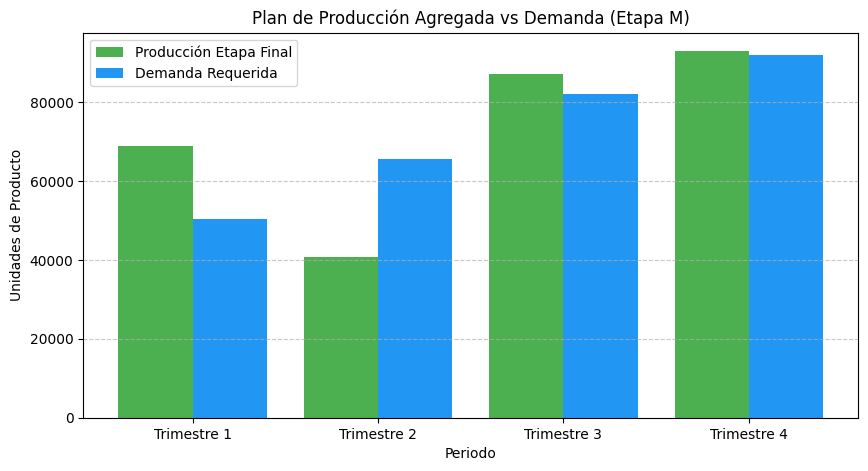


Decisiones de Alistamiento por Máquina (1=Encendida, 0=Apagada):

--- Periodo 1 ---
Etapa 1: Máquinas encendidas -> [1, 2]
Etapa 2: Máquinas encendidas -> [1]
Etapa 3: Máquinas encendidas -> [1, 2]
Etapa 4: Máquinas encendidas -> [1, 2]

--- Periodo 2 ---
Etapa 1: Máquinas encendidas -> [1]
Etapa 2: Máquinas encendidas -> [1]
Etapa 3: Máquinas encendidas -> [1]
Etapa 4: Máquinas encendidas -> [2]

--- Periodo 3 ---
Etapa 1: Máquinas encendidas -> [2, 3]
Etapa 2: Máquinas encendidas -> [1]
Etapa 3: Máquinas encendidas -> [2, 3]
Etapa 4: Máquinas encendidas -> [1, 3]

--- Periodo 4 ---
Etapa 1: Máquinas encendidas -> []
Etapa 2: Máquinas encendidas -> []
Etapa 3: Máquinas encendidas -> []
Etapa 4: Máquinas encendidas -> [3, 4]


In [ ]:
if prob.status == pulp.LpStatusOptimal:
    # Extraer producción de la etapa final (Producto Terminado)
    prod_final = []
    for t in T:
        total_t = sum(X[M[-1], j, t].varValue for j in fuentes[M[-1]])
        prod_final.append(total_t)

    demandas_list = [demanda[t] for t in T]

    # Gráfico de Producción vs Demanda
    x_labels = [f"Trimestre {t}" for t in T]
    x = range(len(T))

    plt.figure(figsize=(10, 5))
    plt.bar([pos - 0.2 for pos in x], prod_final, width=0.4, label='Producción Etapa Final', color='#4CAF50')
    plt.bar([pos + 0.2 for pos in x], demandas_list, width=0.4, label='Demanda Requerida', color='#2196F3')

    plt.title('Plan de Producción Agregada vs Demanda (Etapa M)')
    plt.xlabel('Periodo')
    plt.ylabel('Unidades de Producto')
    plt.xticks(x, x_labels)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    # Opcional: Imprimir tabla de decisiones Y (Qué máquinas encender)
    print("\nDecisiones de Alistamiento por Máquina (1=Encendida, 0=Apagada):")
    for t in T:
        print(f"\n--- Periodo {t} ---")
        for i in M:
            encendidas = [j for j in fuentes[i] if Y[i,j,t].varValue == 1.0]
            print(f"Etapa {i}: Máquinas encendidas -> {encendidas}")
else:
    print("El modelo no encontró una solución óptima. Revisa las capacidades o parámetros.")

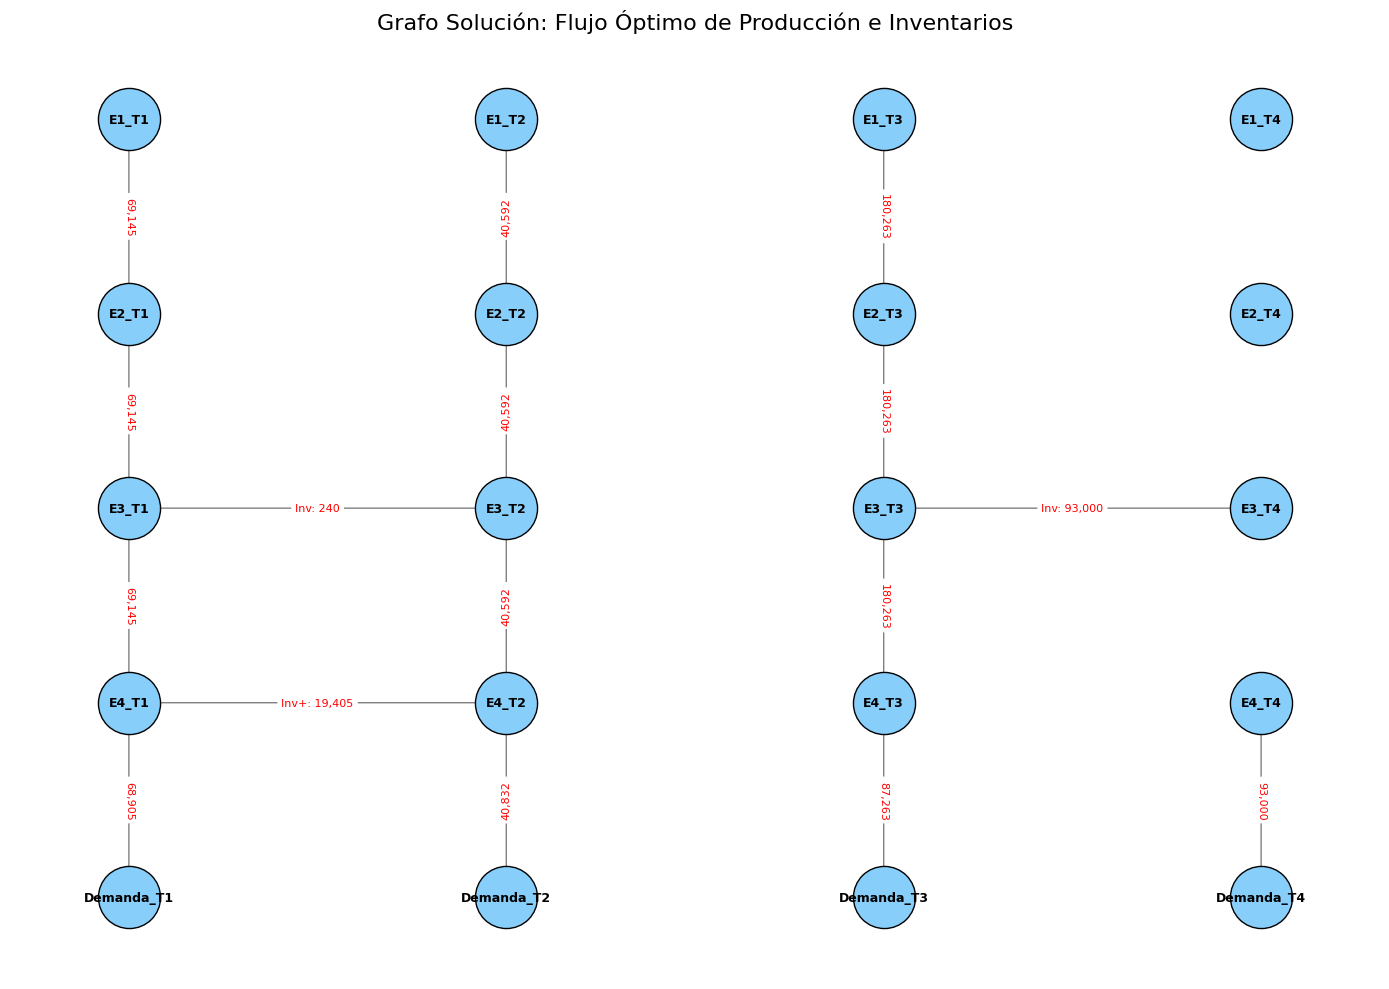

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

if prob.status == pulp.LpStatusOptimal:
    # 1. Crear el grafo dirigido
    G = nx.DiGraph()
    pos = {} # Diccionario para guardar las coordenadas (x,y) de cada nodo

    # 2. Crear los nodos y posicionarlos en forma de matriz/cuadrícula
    for t in T:
        for i in M:
            nodo = f"E{i}_T{t}"
            G.add_node(nodo)
            # x = t (avanza hacia la derecha por trimestre)
            # y = -i (avanza hacia abajo por etapa)
            pos[nodo] = (t * 2, -i * 2)

        # Nodo final (Demanda / Salida del sistema para el trimestre)
        nodo_salida = f"Demanda_T{t}"
        G.add_node(nodo_salida)
        pos[nodo_salida] = (t * 2, -(M[-1] + 1) * 2)

    # 3. Crear las flechas (aristas) basadas en los resultados
    for t in T:
        for i in M:
            # Flujo de Producción (flechas hacia abajo, de etapa i a etapa i+1)
            prod_total = sum(X[i, j, t].varValue for j in fuentes[i])
            if prod_total > 0:
                if i < M[-1]:
                    G.add_edge(f"E{i}_T{t}", f"E{i+1}_T{t}", label=f"{prod_total:,.0f}")
                else:
                    # En la última etapa, la producción va a satisfacer la demanda
                    G.add_edge(f"E{i}_T{t}", f"Demanda_T{t}", label=f"{prod_total:,.0f}")

    # Flujo de Inventario (flechas hacia la derecha, de periodo t a t+1)
    for t in T[:-1]:
        # Inventario en proceso
        for i in M[:-1]:
            inv = I[i, t].varValue
            if inv > 0:
                G.add_edge(f"E{i}_T{t}", f"E{i}_T{t+1}", label=f"Inv: {inv:,.0f}")

        # Inventario Producto Terminado
        inv_pt = I_plus[t].varValue
        if inv_pt > 0:
            G.add_edge(f"E{M[-1]}_T{t}", f"E{M[-1]}_T{t+1}", label=f"Inv+: {inv_pt:,.0f}")

    # 4. Dibujar el Grafo
    plt.figure(figsize=(14, 10))

    # Dibujar nodos
    nx.draw_networkx_nodes(G, pos, node_color='#87CEFA', node_size=2000, edgecolors='black')

    # Dibujar etiquetas de los nodos (Ej: E1_T1)
    nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')

    # Dibujar flechas
    nx.draw_networkx_edges(G, pos, arrowstyle='-|>', arrowsize=20, edge_color='gray')

    # Dibujar los números sobre las flechas (las cantidades óptimas calculadas)
    etiquetas_flechas = nx.get_edge_attributes(G, 'label')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=etiquetas_flechas, font_color='red', font_size=8, label_pos=0.5)

    plt.title("Grafo Solución: Flujo Óptimo de Producción e Inventarios", fontsize=16)
    plt.axis('off') # Ocultar los ejes numéricos del fondo
    plt.tight_layout()
    plt.show()
else:
    print("No se puede generar el grafo sin una solución óptima previa.")